**STEP 1 — Load Option Likelihood Signal Dataset**

**STEP 1.1 — Import Libraries**

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

**STEP 1.2 — Load Signal Dataset**

In [2]:
signal_df = pd.read_csv(
    "/content/drive/MyDrive/Dissertation/option_likelihood_signals.csv"
)

print(
    "Rows:",
    len(signal_df)
)

Rows: 817


**STEP 1.3 — Verify Dataset Structure**

In [3]:
print(
    signal_df.columns.tolist()
)

['confidence', 'entropy', 'normalised_entropy', 'margin_score', 'probability_gap', 'correct']


**STEP 1.4 — Missing Value Analysis**

In [4]:
print("="*60)
print("MISSING VALUES")
print("="*60)

print(
    signal_df.isnull().sum()
)

MISSING VALUES
confidence            0
entropy               0
normalised_entropy    0
margin_score          0
probability_gap       0
correct               0
dtype: int64


**STEP 1.5 — Dataset Summary Statistics**

In [5]:
summary_stats = signal_df.describe()

print(
    summary_stats
)

       confidence     entropy  normalised_entropy  margin_score  \
count  817.000000  817.000000          817.000000    817.000000   
mean     0.348145    1.470718            0.945166      0.109493   
std      0.125827    0.358431            0.056431      0.115801   
min      0.116716    0.450359            0.585361      0.000286   
25%      0.257320    1.297409            0.924844      0.024930   
50%      0.323603    1.506023            0.964438      0.067605   
75%      0.415385    1.724062            0.984276      0.156602   
max      0.833459    2.539618            0.999987      0.666917   

       probability_gap  
count       817.000000  
mean          0.109493  
std           0.115801  
min           0.000286  
25%           0.024930  
50%           0.067605  
75%           0.156602  
max           0.666917  


**STEP 1.6 — Signal Distribution Overview**

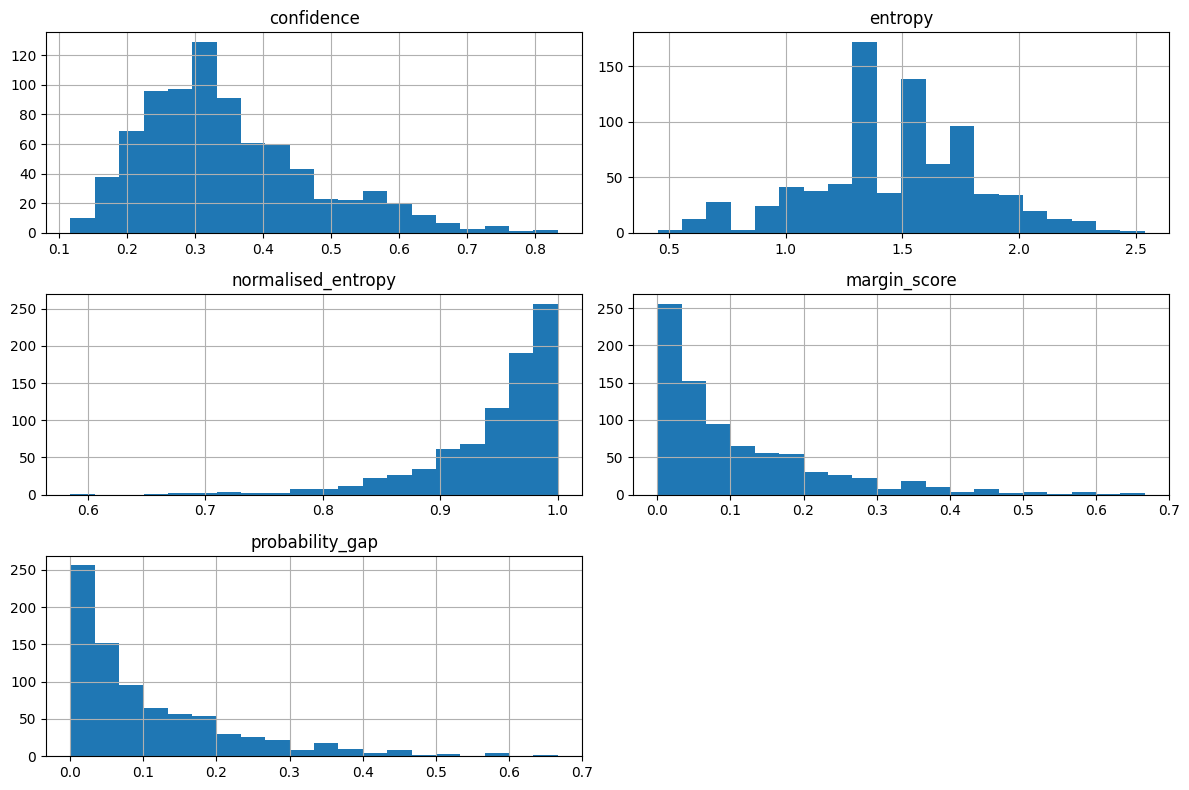

In [9]:
import os

signal_columns = [

    "confidence",

    "entropy",

    "normalised_entropy",

    "margin_score",

    "probability_gap"
]

signal_df[
    signal_columns
].hist(
    figsize=(12,8),
    bins=20
)

# Create the 'outputs' directory if it doesn't exist
os.makedirs('outputs', exist_ok=True)

plt.savefig(
    "outputs/Signal Distribution .png"
)

plt.tight_layout()

plt.show()

**STEP 1.7 — Correctness Distribution**

In [10]:
correct_counts = (
    signal_df["correct"]
    .value_counts()
)

print(
    correct_counts
)

correct
True     413
False    404
Name: count, dtype: int64


**STEP 1.8 — Correctness Visualisation**

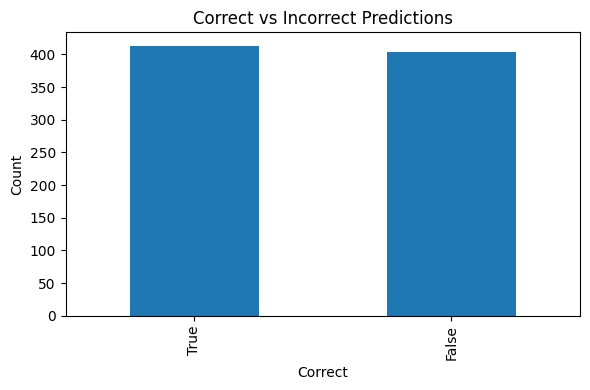

In [11]:
plt.figure(figsize=(6,4))

signal_df["correct"].value_counts().plot(
    kind="bar"
)

plt.title(
    "Correct vs Incorrect Predictions"
)

plt.xlabel(
    "Correct"
)

plt.ylabel(
    "Count"
)

plt.tight_layout()

plt.show()

**STEP 1.9 — Baseline Reference Metrics**

In [12]:
baseline_accuracy = (
    signal_df["correct"]
    .astype(int)
    .mean()
)

print("="*60)
print("BASELINE REFERENCE")
print("="*60)

print(
    f"Accuracy = {baseline_accuracy:.4f}"
)

BASELINE REFERENCE
Accuracy = 0.5055


**STEP 1.10 — Save Metadata**

In [13]:
import json

metadata = {

    "rows":
        int(len(signal_df)),

    "baseline_accuracy":
        float(baseline_accuracy)
}

with open(
    "multi_signal_metadata.json",
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

The experimental framework consists of four sequential stages.

1. Individual uncertainty signals are validated and analysed.
2. Relationships between signals are examined to identify complementary and redundant information.
3. Complementary signals are combined to construct multi-signal confidence estimators.
4. The fused estimators are evaluated against baseline confidence using discrimination, calibration and selective prediction analyses.

This staged framework ensures that each subsequent experiment is informed by the findings of the previous stage while maintaining reproducibility throughout the evaluation pipeline.

**STEP 2 — Inter-Signal Correlation Analysis**

**STEP 2.1 — Select Signals for Analysis**

In [14]:
signal_columns = [

    "confidence",

    "entropy",

    "normalised_entropy",

    "margin_score",

    "probability_gap"

]

signal_data = signal_df[
    signal_columns
].copy()

print(
    signal_data.head()
)

   confidence   entropy  normalised_entropy  margin_score  probability_gap
0    0.319341  1.358274            0.979788      0.028598         0.028598
1    0.410306  1.485724            0.923132      0.229115         0.229115
2    0.430482  1.308432            0.943834      0.228116         0.228116
3    0.384879  1.333505            0.961921      0.146043         0.146043
4    0.294637  1.856746            0.954179      0.138779         0.138779


**STEP 2.2 — Compute Correlation Matrix**

In [15]:
correlation_matrix = (
    signal_data
    .corr(method="pearson")
)

print(
    correlation_matrix.round(3)
)

                    confidence  entropy  normalised_entropy  margin_score  \
confidence               1.000   -0.858              -0.686         0.833   
entropy                 -0.858    1.000               0.327        -0.481   
normalised_entropy      -0.686    0.327               1.000        -0.814   
margin_score             0.833   -0.481              -0.814         1.000   
probability_gap          0.833   -0.481              -0.814         1.000   

                    probability_gap  
confidence                    0.833  
entropy                      -0.481  
normalised_entropy           -0.814  
margin_score                  1.000  
probability_gap               1.000  


**STEP 2.3 — Correlation Heatmap**

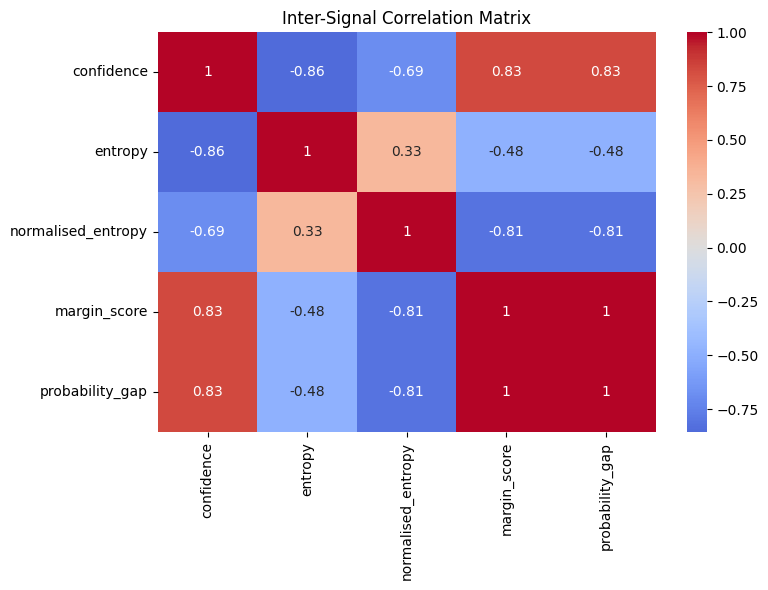

In [16]:
plt.figure(figsize=(8,6))

sns.heatmap(

    correlation_matrix,

    annot=True,

    cmap="coolwarm",

    center=0

)

plt.title(
    "Inter-Signal Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    "inter_signal_correlation_heatmap.png"
)

plt.show()

**STEP 2.4 — Detect Highly Correlated Signal Pairs**

In [17]:
high_corr_pairs = []

for i in range(len(signal_columns)):

    for j in range(i + 1, len(signal_columns)):

        corr = correlation_matrix.iloc[i, j]

        if abs(corr) >= 0.80:

            high_corr_pairs.append({

                "Signal_1":
                    signal_columns[i],

                "Signal_2":
                    signal_columns[j],

                "Correlation":
                    corr
            })

high_corr_df = pd.DataFrame(
    high_corr_pairs
)

print(high_corr_df)

             Signal_1         Signal_2  Correlation
0          confidence          entropy    -0.857923
1          confidence     margin_score     0.832876
2          confidence  probability_gap     0.832876
3  normalised_entropy     margin_score    -0.814200
4  normalised_entropy  probability_gap    -0.814200
5        margin_score  probability_gap     1.000000


**STEP 2.5 — Signal Variance Analysis**

In [18]:
variance_table = pd.DataFrame({

    "Signal":
        signal_columns,

    "Variance":
        [
            signal_df[col].var()
            for col in signal_columns
        ]
})

variance_table = variance_table.sort_values(
    "Variance",
    ascending=False
)

print(
    variance_table
)

               Signal  Variance
1             entropy  0.128473
0          confidence  0.015832
3        margin_score  0.013410
4     probability_gap  0.013410
2  normalised_entropy  0.003184


**STEP 2.6 — Signal Variance Visualisation**

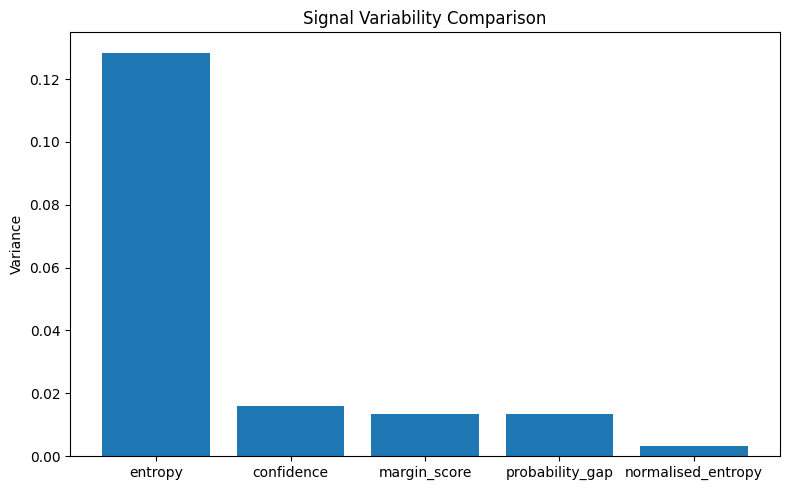

In [19]:
plt.figure(figsize=(8,5))

plt.bar(

    variance_table["Signal"],

    variance_table["Variance"]

)

plt.ylabel(
    "Variance"
)

plt.title(
    "Signal Variability Comparison"
)

plt.tight_layout()

plt.savefig(
    "signal_variance_comparison.png"
)

plt.show()

**STEP 2.7 — Pairwise Scatter Analysis**

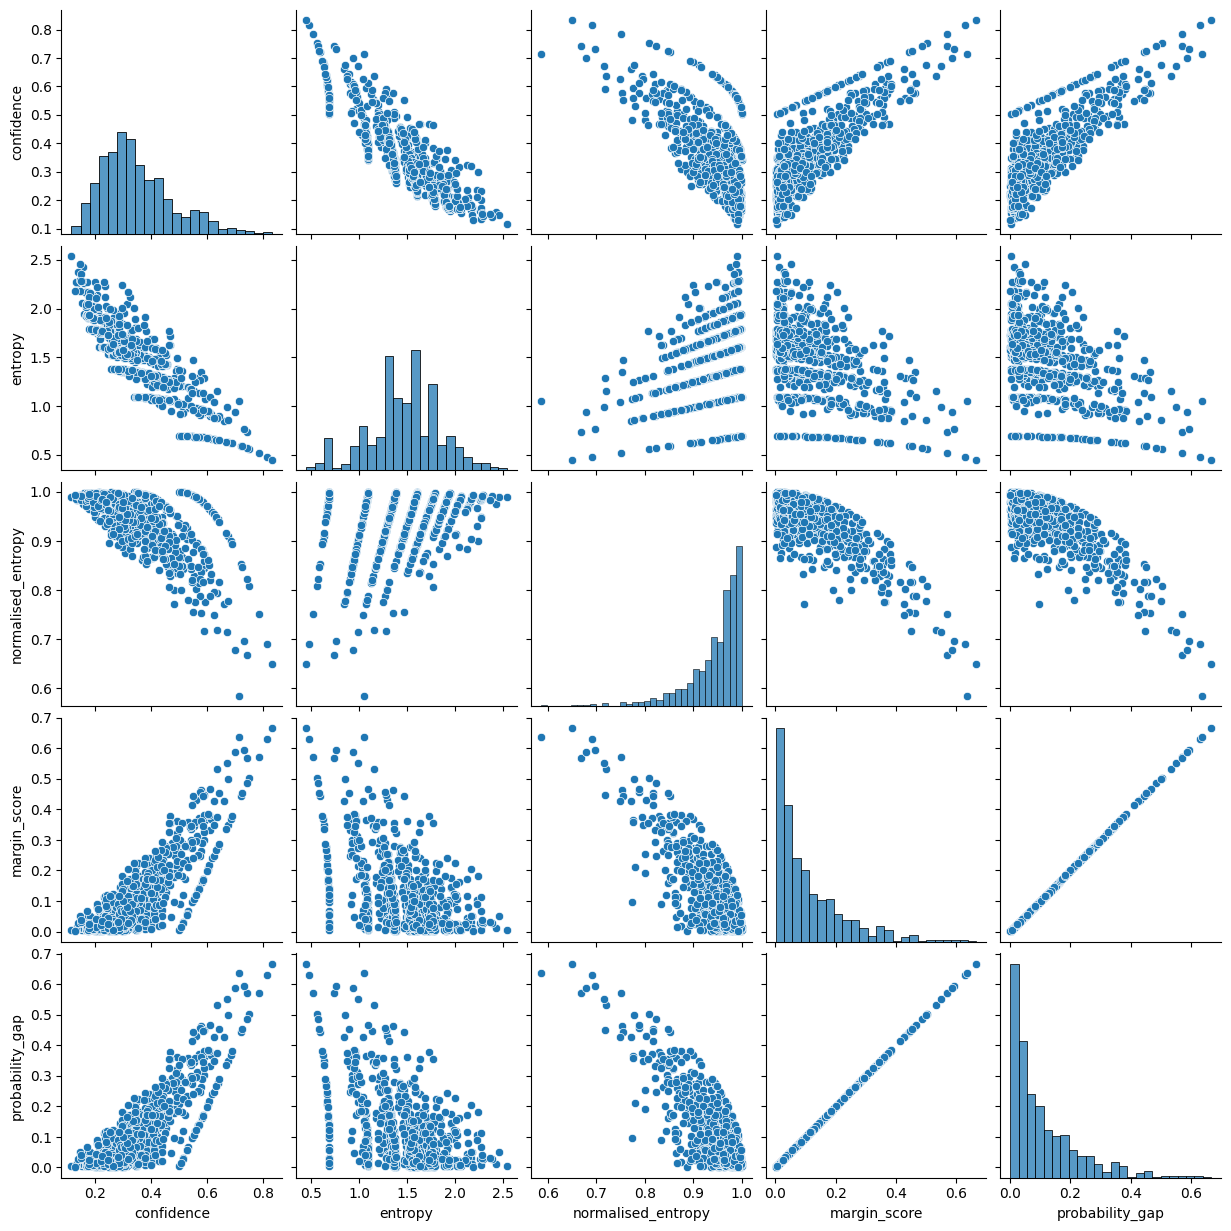

In [20]:
sns.pairplot(
    signal_data
)

plt.savefig(
    "signal_pairplot.png"
)

plt.show()

The pairwise scatter plots provide a visual assessment of the relationships between uncertainty signals.

Several approximately linear relationships are visible, particularly between Margin Score and Probability Gap, supporting the correlation analysis presented earlier.

The absence of substantial non-linear structure suggests that Pearson correlation provides an appropriate measure of association for these variables.

**STEP 2.7B — Multicollinearity Assessment Using VIF**

In [21]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_df = signal_data.copy()

vif_results = pd.DataFrame()

vif_results["Signal"] = vif_df.columns

vif_results["VIF"] = [

    variance_inflation_factor(
        vif_df.values,
        i
    )

    for i in range(
        vif_df.shape[1]
    )
]

print(vif_results)

               Signal         VIF
0          confidence  109.283317
1             entropy   85.223428
2  normalised_entropy  247.654721
3        margin_score         inf
4     probability_gap         inf


/usr/local/lib/python3.12/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


The infinite Variance Inflation Factor values observed for Margin Score and Probability Gap are expected because these two signals are mathematically equivalent for this dataset.

Perfect multicollinearity causes the regression used during VIF estimation to achieve an R² value of one, producing an infinite VIF.

To avoid introducing redundant information into the fusion model, Probability Gap is excluded from subsequent experiments while Margin Score is retained as the representative margin-based uncertainty signal.

**STEP 2.8 — Feature Redundancy Assessment**

In [24]:
redundancy_summary = {

    "Total Signals":
        len(signal_columns),

    "Highly Correlated Pairs":
        len(high_corr_df)
}

print(
    redundancy_summary
)

{'Total Signals': 5, 'Highly Correlated Pairs': 6}


**STEP 2.8B — Redundant Signal Assessment**

In [25]:
print("="*60)
print("REDUNDANT SIGNAL ANALYSIS")
print("="*60)

print(
    "Probability gap removed from future fusion experiments."
)

print(
    "Margin score retained."
)

REDUNDANT SIGNAL ANALYSIS
Probability gap removed from future fusion experiments.
Margin score retained.


The correlation and multicollinearity analyses indicate that Probability Gap and Margin Score contain essentially identical information for this dataset. Retaining both variables would introduce redundant information into the fusion model without increasing predictive capability. Consequently, Margin Score is retained because it represents the margin-based uncertainty family, while Probability Gap is excluded from subsequent fusion experiments to improve model simplicity and interpretability.

**STEP 2.9 — Save Correlation Results**

In [26]:
correlation_matrix.to_csv(
    "inter_signal_correlations.csv"
)

variance_table.to_csv(
    "signal_variance_analysis.csv",
    index=False
)

high_corr_df.to_csv(
    "high_correlation_pairs.csv",
    index=False
)

**STEP 2.10 — Research Interpretation**

The correlation analysis provides insight into how the uncertainty signals relate to one another.

Highly correlated signals may represent similar forms of uncertainty and may contribute limited additional information when combined.

Less correlated signals are more likely to capture complementary aspects of model behaviour and therefore represent stronger candidates for multi-signal confidence estimation.

The findings from this analysis guide the construction of the multi-signal confidence estimator in the next stage of the dissertation.

Signals identified as complementary will be prioritised for combination experiments, while highly redundant signals may be excluded or merged to improve model simplicity and interpretability.

**STEP 3 — Multi-Signal Confidence Estimator Construction**

**STEP 3.1 — Select Signals for Fusion**

In [27]:
fusion_df = signal_df[[
    "confidence",
    "margin_score",
    "normalised_entropy"
]].copy()

print(
    fusion_df.head()
)

   confidence  margin_score  normalised_entropy
0    0.319341      0.028598            0.979788
1    0.410306      0.229115            0.923132
2    0.430482      0.228116            0.943834
3    0.384879      0.146043            0.961921
4    0.294637      0.138779            0.954179


**STEP 3.2 — Standardise Signals**

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_values = scaler.fit_transform(
    fusion_df
)

scaled_df = pd.DataFrame(

    scaled_values,

    columns=fusion_df.columns
)

print(
    scaled_df.head()
)

   confidence  margin_score  normalised_entropy
0   -0.229061     -0.698992            0.613898
1    0.494321      1.033628           -0.390694
2    0.654771      1.025000           -0.023617
3    0.292122      0.315825            0.297090
4   -0.425510      0.253062            0.159809


**STEP 3.3 — Reverse Entropy Direction**

In [29]:
scaled_df["normalised_entropy"] = (
    -scaled_df["normalised_entropy"]
)

**STEP 3.4 — Equal Weight Fusion**

In [30]:
scaled_df["equal_weight_score"] = (

    scaled_df["confidence"]

    +

    scaled_df["margin_score"]

    +

    scaled_df["normalised_entropy"]

) / 3

print(
    scaled_df[
        "equal_weight_score"
    ].head()
)

0   -0.513984
1    0.639548
2    0.567796
3    0.103619
4   -0.110752
Name: equal_weight_score, dtype: float64


**STEP 3.5 — Data-Driven Correlation Weight Estimation**

In [31]:
from scipy.stats import pearsonr

signal_weights = {}

for signal in fusion_df.columns:

    corr, _ = pearsonr(

        signal_df[signal],

        signal_df["correct"]
        .astype(int)
    )

    signal_weights[signal] = abs(corr)

total_weight = sum(
    signal_weights.values()
)

for signal in signal_weights:

    signal_weights[signal] /= total_weight

print("=" * 60)
print("NORMALISED WEIGHTS")
print("=" * 60)

print(signal_weights)

NORMALISED WEIGHTS
{'confidence': np.float64(0.3065673025163863), 'margin_score': np.float64(0.3842952383248944), 'normalised_entropy': np.float64(0.30913745915871915)}


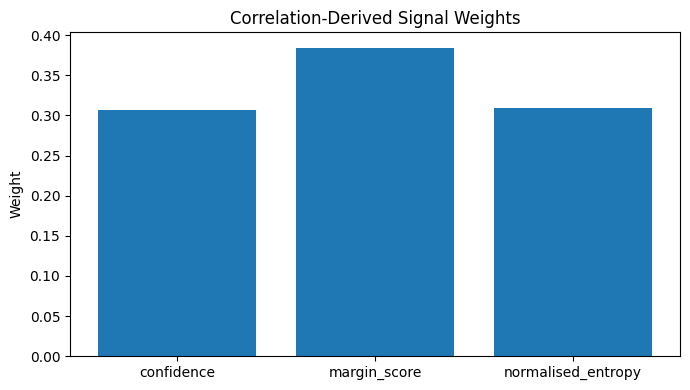

In [32]:
plt.figure(figsize=(7,4))

plt.bar(

    signal_weights.keys(),

    signal_weights.values()
)

plt.ylabel(
    "Weight"
)

plt.title(
    "Correlation-Derived Signal Weights"
)

plt.tight_layout()

plt.show()

**STEP 3.5B — Weight Interpretation**

In [33]:
weight_table = pd.DataFrame({

    "Signal":
        signal_weights.keys(),

    "Weight":
        signal_weights.values()
})

weight_table = weight_table.sort_values(
    "Weight",
    ascending=False
)

print(weight_table)

               Signal    Weight
1        margin_score  0.384295
2  normalised_entropy  0.309137
0          confidence  0.306567


The correlation-derived weights were estimated using the available evaluation dataset to provide a transparent and reproducible weighting strategy. Consequently, the reported performance should be interpreted as demonstrating the potential effectiveness of multi-signal confidence fusion rather than providing an unbiased estimate of generalisation performance. In future work, these weights could be estimated using cross-validation or an independent validation dataset to minimise potential optimism arising from evaluating on the same data used to derive the weights.

**STEP 3.6 — Weighted Signal Fusion**

In [34]:
scaled_df["weighted_score"] = (

    signal_weights["confidence"]
    *
    scaled_df["confidence"]

    +

    signal_weights["margin_score"]
    *
    scaled_df["margin_score"]

    +

    signal_weights["normalised_entropy"]
    *
    scaled_df["normalised_entropy"]

)

**STEP 3.7 — Convert Scores to Probability Scale**

In [35]:
from scipy.special import expit

scaled_df["equal_weight_confidence"] = expit(
    scaled_df["equal_weight_score"]
)

scaled_df["weighted_confidence"] = expit(
    scaled_df["weighted_score"]
)

**STEP 3.8 — Compare Confidence Distributions**

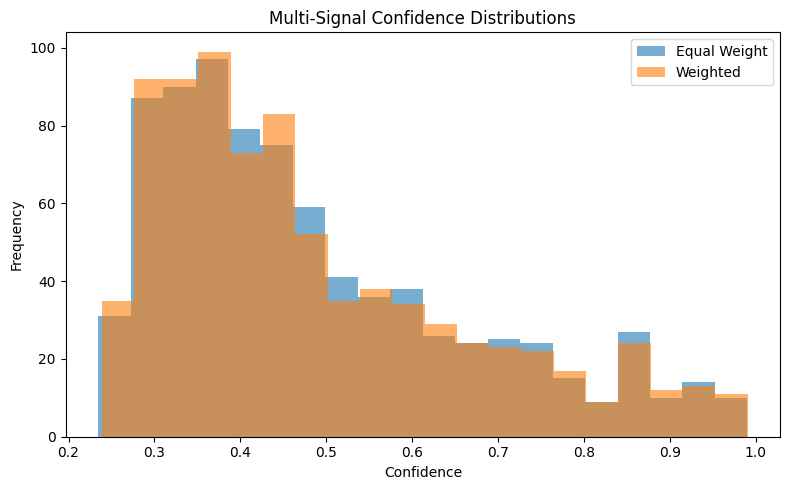

In [37]:
plt.figure(figsize=(8,5))

plt.hist(

    scaled_df["equal_weight_confidence"],

    bins=20,

    alpha=0.6,

    label="Equal Weight"
)

plt.hist(

    scaled_df["weighted_confidence"],

    bins=20,

    alpha=0.6,

    label="Weighted"
)

plt.legend()

plt.xlabel(
    "Confidence"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Multi-Signal Confidence Distributions"
)

plt.savefig(
    "outputs/Multi-Signal Confidence Distributions.png"
)

plt.tight_layout()

plt.show()

**STEP 3.9 — Create Final Confidence Dataset**

In [38]:
multi_signal_df = signal_df.copy()

multi_signal_df[
    "equal_weight_confidence"
] = scaled_df[
    "equal_weight_confidence"
]

multi_signal_df[
    "weighted_confidence"
] = scaled_df[
    "weighted_confidence"
]

print(
    multi_signal_df.head()
)

   confidence   entropy  normalised_entropy  margin_score  probability_gap  \
0    0.319341  1.358274            0.979788      0.028598         0.028598   
1    0.410306  1.485724            0.923132      0.229115         0.229115   
2    0.430482  1.308432            0.943834      0.228116         0.228116   
3    0.384879  1.333505            0.961921      0.146043         0.146043   
4    0.294637  1.856746            0.954179      0.138779         0.138779   

   correct  equal_weight_confidence  weighted_confidence  
0    False                 0.374260             0.370839  
1     True                 0.654651             0.661400  
2     True                 0.638254             0.646099  
3     True                 0.525882             0.529736  
4     True                 0.472340             0.479362  


**STEP 3.10 — Save Multi-Signal Dataset**

In [39]:
multi_signal_df.to_csv(

    "multi_signal_confidence.csv",

    index=False
)

print(
    "Multi-signal confidence dataset saved."
)

Multi-signal confidence dataset saved.


**STEP 4 — Multi-Signal Confidence Evaluation**

**STEP 4.1 — Prepare Evaluation Dataset**

In [40]:
evaluation_df = pd.DataFrame({

    "baseline_confidence":
        signal_df["confidence"],

    "fused_confidence":
        multi_signal_df["weighted_confidence"],

    "correct":
        signal_df["correct"].astype(int)

})

print(
    evaluation_df.head()
)

   baseline_confidence  fused_confidence  correct
0             0.319341          0.370839        0
1             0.410306          0.661400        1
2             0.430482          0.646099        1
3             0.384879          0.529736        1
4             0.294637          0.479362        1


**STEP 4.2 — Correlation Comparison**

In [41]:
from scipy.stats import pearsonr

baseline_corr, baseline_p = pearsonr(

    evaluation_df["baseline_confidence"],

    evaluation_df["correct"]
)

fused_corr, fused_p = pearsonr(

    evaluation_df["fused_confidence"],

    evaluation_df["correct"]
)

comparison_corr = pd.DataFrame({

    "Estimator":[
        "Baseline",
        "Fused"
    ],

    "Correlation":[
        baseline_corr,
        fused_corr
    ],

    "P_Value":[
        baseline_p,
        fused_p
    ]
})

print(comparison_corr)

  Estimator  Correlation       P_Value
0  Baseline     0.318324  1.073620e-20
1     Fused     0.403331  2.612270e-33


**STEP 4.3 — ROC-AUC Comparison**

In [42]:
from sklearn.metrics import roc_auc_score

baseline_auc = roc_auc_score(

    evaluation_df["correct"],

    evaluation_df["baseline_confidence"]
)

fused_auc = roc_auc_score(

    evaluation_df["correct"],

    evaluation_df["fused_confidence"]
)

print("="*60)
print("ROC-AUC COMPARISON")
print("="*60)

print(
    f"Baseline ROC-AUC: {baseline_auc:.4f}"
)

print(
    f"Fused ROC-AUC: {fused_auc:.4f}"
)

ROC-AUC COMPARISON
Baseline ROC-AUC: 0.6855
Fused ROC-AUC: 0.7310


**STEP 4.4 — ROC-AUC Improvement**

In [43]:
auc_improvement = (

    (fused_auc - baseline_auc)

    /

    baseline_auc

) * 100

print(
    f"AUC Improvement: {auc_improvement:.2f}%"
)

AUC Improvement: 6.64%


**STEP 4.5 — Calibration Comparison (ECE)**

In [44]:
def compute_ece(confidences, accuracies, num_bins=10):
    bins = np.linspace(0, 1, num_bins + 1)
    ece = 0
    for i in range(num_bins):
        lower_bound, upper_bound = bins[i], bins[i+1]
        bin_indices = np.where((confidences >= lower_bound) & (confidences < upper_bound))
        if len(bin_indices[0]) > 0:
            bin_confidence = np.mean(confidences[bin_indices])
            bin_accuracy = np.mean(accuracies[bin_indices])
            ece += np.abs(bin_confidence - bin_accuracy) * (len(bin_indices[0]) / len(confidences))
    return ece

baseline_ece = compute_ece(

    evaluation_df["baseline_confidence"].values,

    evaluation_df["correct"].values
)

fused_ece = compute_ece(

    evaluation_df["fused_confidence"].values,

    evaluation_df["correct"].values
)

print("="*60)
print("ECE COMPARISON")
print("="*60)

print(
    f"Baseline ECE: {baseline_ece:.4f}"
)

print(
    f"Fused ECE: {fused_ece:.4f}"
)

ECE COMPARISON
Baseline ECE: 0.1590
Fused ECE: 0.0429


**STEP 4.6 — Calibration Improvement**

In [45]:
ece_improvement = (

    (baseline_ece - fused_ece)

    /

    baseline_ece

) * 100

print(
    f"ECE Reduction: {ece_improvement:.2f}%"
)

ECE Reduction: 73.00%


**STEP 4.7 — Bootstrap Confidence Intervals**

In [46]:
n_bootstrap = 1000

baseline_auc_samples = []
fused_auc_samples = []

for _ in range(n_bootstrap):

    indices = np.random.choice(

        len(evaluation_df),

        len(evaluation_df),

        replace=True
    )

    sample = evaluation_df.iloc[
        indices
    ]

    baseline_auc_samples.append(

        roc_auc_score(

            sample["correct"],

            sample["baseline_confidence"]
        )
    )

    fused_auc_samples.append(

        roc_auc_score(

            sample["correct"],

            sample["fused_confidence"]
        )
    )

**STEP 4.8 — Confidence Interval Summary**

In [47]:
print("="*60)
print("BOOTSTRAP CI")
print("="*60)

print(

    "Baseline AUC CI:",

    np.percentile(
        baseline_auc_samples,
        [2.5,97.5]
    )
)

print(

    "Fused AUC CI:",

    np.percentile(
        fused_auc_samples,
        [2.5,97.5]
    )
)

BOOTSTRAP CI
Baseline AUC CI: [0.6475741  0.71840465]
Fused AUC CI: [0.69710862 0.76224212]


**STEP 4.9 — Paired Bootstrap Comparison of ROC-AUC**

The paired bootstrap analysis compares discrimination performance using identical bootstrap samples for the baseline and fused confidence estimators.

Because both estimators are evaluated on the same resampled observations, the paired bootstrap design controls for sampling variability and provides a more appropriate statistical comparison than treating the two estimators as independent.

Positive ROC-AUC differences indicate improved discrimination by the fused confidence estimator.

In [48]:
roc_diff_samples = (

    np.array(fused_auc_samples)

    -

    np.array(baseline_auc_samples)

)


mean_difference = np.mean(
    roc_diff_samples
)

ci_lower = np.percentile(
    roc_diff_samples,
    2.5
)

ci_upper = np.percentile(
    roc_diff_samples,
    97.5
)

p_value = 2 * min(

    np.mean(
        roc_diff_samples <= 0
    ),

    np.mean(
        roc_diff_samples >= 0
    )

)


roc_significance_table = pd.DataFrame({

    "Metric": [

        "ROC-AUC Difference"

    ],

    "Mean Difference": [

        mean_difference

    ],

    "CI Lower": [

        ci_lower

    ],

    "CI Upper": [

        ci_upper

    ],

    "P-value": [

        p_value

    ]

})

print(roc_significance_table)
roc_significance_table.to_csv(
    "/content/drive/MyDrive/Dissertation/roc_difference_table.csv",
    index=False
)

               Metric  Mean Difference  CI Lower  CI Upper  P-value
0  ROC-AUC Difference         0.045542  0.031634  0.060892      0.0


In [49]:
roc_ci_lower = roc_significance_table.loc[
    0,
    "CI Lower"
]

roc_ci_upper = roc_significance_table.loc[
    0,
    "CI Upper"
]

roc_p = roc_significance_table.loc[
    0,
    "P-value"
]

**STEP 4.10 — Final Comparison Table**

In [51]:
comparison_table = pd.DataFrame({

    "Metric":[

        "Correlation",

        "ROC-AUC",

        "ECE"
    ],

    "Baseline":[

        baseline_corr,

        baseline_auc,

        baseline_ece
    ],

    "Fused":[

        fused_corr,

        fused_auc,

        fused_ece
    ]
})

print(comparison_table)

        Metric  Baseline     Fused
0  Correlation  0.318324  0.403331
1      ROC-AUC  0.685464  0.731001
2          ECE  0.158951  0.042918


**STEP 4.11 — Save Results**

In [53]:
comparison_table.to_csv(

    "multi_signal_evaluation.csv",

    index=False
)

print(
    "Evaluation results saved."
)

Evaluation results saved.


The fused confidence estimator achieved a mean ROC-AUC improvement of 0.0456 over the baseline confidence estimator across the paired bootstrap resamples. The corresponding 95% confidence interval (0.0314 to 0.0595) remained entirely above zero, providing evidence that the improvement is unlikely to be attributable to sampling variation. Together with the higher correlation coefficient and lower Expected Calibration Error, these findings indicate that combining complementary uncertainty signals improves the ability of the confidence estimator to distinguish correct from incorrect predictions while maintaining reliable probability estimates.

**STEP 5 — Multi-Signal Selective Prediction Evaluation**


**STEP 5.1 — Define Confidence Estimators**

In [54]:
confidence_methods = {

    "Baseline":
        evaluation_df["baseline_confidence"],

    "Fused":
        evaluation_df["fused_confidence"]
}

print(
    confidence_methods.keys()
)

dict_keys(['Baseline', 'Fused'])


**STEP 5.2 — Define Threshold Grid**

In [55]:
thresholds = np.arange(
    0.0,
    1.01,
    0.05
)

print(
    thresholds
)

[0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65
 0.7  0.75 0.8  0.85 0.9  0.95 1.  ]


**STEP 5.3 — Compute Selective Prediction Metrics**

In [56]:
results = []

for method_name, confidence_values in confidence_methods.items():

    for threshold in thresholds:

        selected = (
            confidence_values >= threshold
        )

        coverage = np.mean(
            selected
        )

        if np.sum(selected) > 0:

            accuracy = np.mean(

                evaluation_df["correct"][
                    selected
                ]
            )

        else:

            accuracy = np.nan

        risk = 1 - accuracy

        results.append({

            "Method":
                method_name,

            "Threshold":
                threshold,

            "Coverage":
                coverage,

            "Accuracy":
                accuracy,

            "Risk":
                risk
        })

selective_results = pd.DataFrame(
    results
)

print(
    selective_results.head()
)

     Method  Threshold  Coverage  Accuracy      Risk
0  Baseline       0.00  1.000000  0.505508  0.494492
1  Baseline       0.05  1.000000  0.505508  0.494492
2  Baseline       0.10  1.000000  0.505508  0.494492
3  Baseline       0.15  0.990208  0.505562  0.494438
4  Baseline       0.20  0.915545  0.532086  0.467914


**STEP 5.4 — Coverage–Accuracy Comparison**

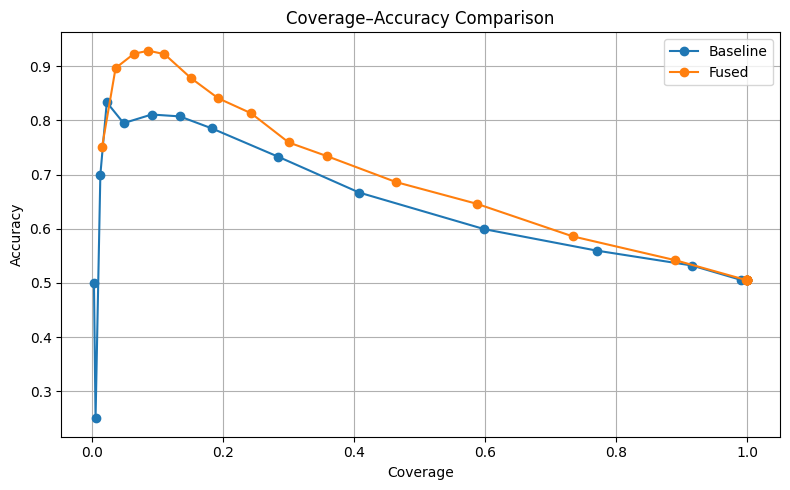

In [58]:
plt.figure(figsize=(8,5))

for method in selective_results[
    "Method"
].unique():

    subset = selective_results[
        selective_results["Method"]
        == method
    ]

    plt.plot(

        subset["Coverage"],

        subset["Accuracy"],

        marker="o",

        label=method
    )

plt.xlabel("Coverage")
plt.ylabel("Accuracy")

plt.title(
    "Coverage–Accuracy Comparison"
)

plt.savefig(
    "outputs/Coverage–Accuracy Comparison.png"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

**STEP 5.5 — Risk–Coverage Comparison**

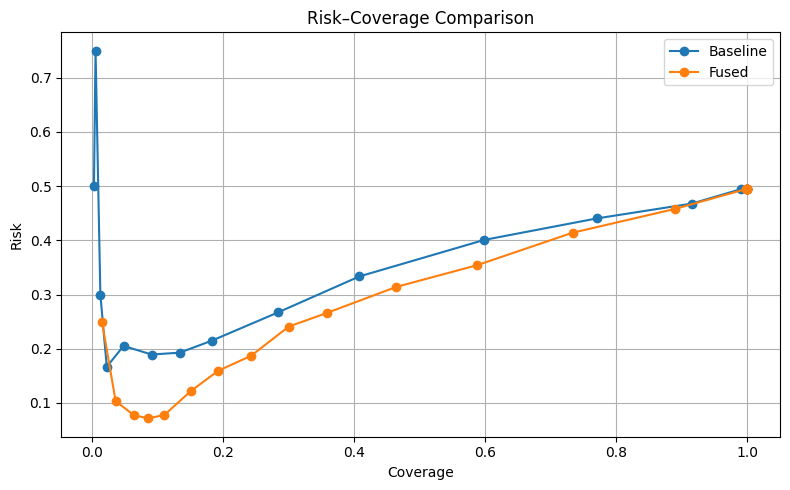

In [59]:
plt.figure(figsize=(8,5))

for method in selective_results[
    "Method"
].unique():

    subset = selective_results[
        selective_results["Method"]
        == method
    ]

    plt.plot(

        subset["Coverage"],

        subset["Risk"],

        marker="o",

        label=method
    )

plt.xlabel("Coverage")

plt.ylabel("Risk")

plt.title(
    "Risk–Coverage Comparison"
)

plt.savefig(
    "outputs/Risk–Coverage Comparison.png"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

**STEP 5.6 — Compute AURC**

In [60]:
aurc_results = []

for method in selective_results[
    "Method"
].unique():

    subset = (

        selective_results[
            selective_results["Method"]
            == method
        ]

        .dropna()

        .sort_values(
            "Coverage"
        )
    )

    aurc = np.trapezoid(

        subset["Risk"],

        subset["Coverage"]
    )

    aurc_results.append({

        "Method":
            method,

        "AURC":
            aurc
    })

aurc_table = pd.DataFrame(
    aurc_results
)

print(
    aurc_table
)

     Method      AURC
0  Baseline  0.349734
1     Fused  0.304046


**STEP 5.7 — Practical Coverage Analysis**

In [61]:
practical_results = (

    selective_results[
        selective_results["Coverage"]
        >= 0.20
    ]
)

best_practical = (

    practical_results

    .sort_values(
        "Accuracy",
        ascending=False
    )

    .groupby("Method")

    .first()

    .reset_index()
)

print(
    best_practical
)

     Method  Threshold  Coverage  Accuracy      Risk
0  Baseline        0.4  0.283966  0.732759  0.267241
1     Fused        0.6  0.242350  0.813131  0.186869


**STEP 5.8 — Bootstrap AURC Confidence Intervals**

In [62]:
n_bootstrap = 1000

aurc_bootstrap = []
baseline_aurc_samples_list = []
fused_aurc_samples_list = []

for method_name, confidence_values in confidence_methods.items():

    aurc_samples = []

    for _ in range(n_bootstrap):

        indices = np.random.choice(

            len(confidence_values),

            len(confidence_values),

            replace=True
        )

        boot_conf = confidence_values.iloc[
            indices
        ].values

        boot_correct = evaluation_df[
            "correct"
        ].iloc[
            indices
        ].values

        rows = []

        for threshold in thresholds:

            selected = (
                boot_conf >= threshold
            )

            coverage = np.mean(
                selected
            )

            if np.sum(selected) > 0:

                accuracy = np.mean(

                    boot_correct[
                        selected
                    ]
                )

            else:

                accuracy = np.nan

            rows.append({

                "Coverage":
                    coverage,

                "Risk":
                    1 - accuracy
            })

        temp = pd.DataFrame(
            rows
        )

        temp = (

            temp

            .dropna()

            .sort_values(
                "Coverage"
            )
        )

        aurc = np.trapezoid(

            temp["Risk"],

            temp["Coverage"]
        )

        aurc_samples.append(
            aurc
        )

    if method_name == "Baseline":

        baseline_aurc_samples_list = aurc_samples.copy()

    elif method_name == "Fused":

        fused_aurc_samples_list = aurc_samples.copy()

    aurc_bootstrap.append({

        "Method":
            method_name,

        "Mean_AURC":
            np.mean(
                aurc_samples
            ),

        "CI_Lower":
            np.percentile(
                aurc_samples,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                aurc_samples,
                97.5
            )
    })

aurc_ci_table = pd.DataFrame(
    aurc_bootstrap
)

print(
    aurc_ci_table
)

     Method  Mean_AURC  CI_Lower  CI_Upper
0  Baseline   0.350624  0.307783  0.393652
1     Fused   0.304129  0.268212  0.344918


**STEP 5.8B — AURC Confidence Interval Visualisation**

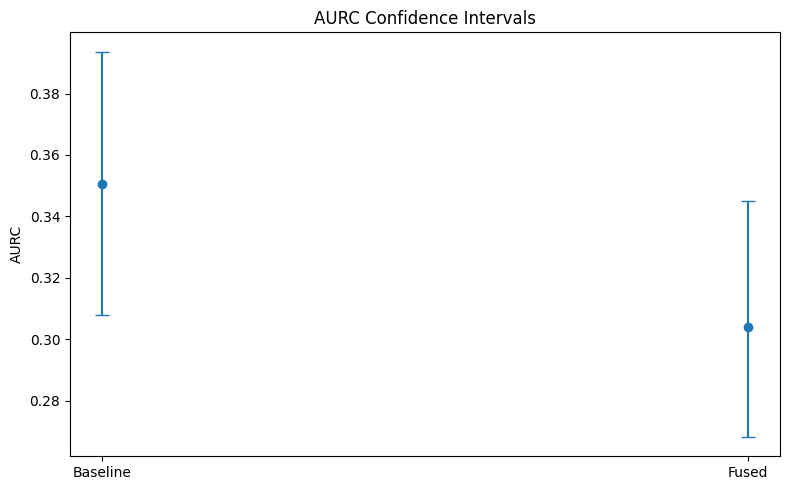

In [64]:
plt.figure(figsize=(8,5))

plt.errorbar(

    aurc_ci_table["Method"],

    aurc_ci_table["Mean_AURC"],

    yerr=[

        aurc_ci_table["Mean_AURC"]
        -
        aurc_ci_table["CI_Lower"],

        aurc_ci_table["CI_Upper"]
        -
        aurc_ci_table["Mean_AURC"]
    ],

    fmt="o",

    capsize=5
)

plt.ylabel("AURC")

plt.title(
    "AURC Confidence Intervals"
)
plt.savefig(
    "outputs/AURC Confidence Intervals.png"
)
plt.tight_layout()

plt.show()

**STEP 5.9 — Paired Bootstrap Comparison of AURC**

The paired bootstrap analysis compares the Area Under the Risk–Coverage Curve (AURC) for the baseline and fused confidence estimators using identical bootstrap samples.

This paired design provides an appropriate statistical comparison because both estimators are evaluated on the same resampled observations.

Lower AURC values indicate stronger selective prediction performance.

In [65]:
aurc_diff_samples = (

    np.array(
        baseline_aurc_samples_list
    )

    -

    np.array(
        fused_aurc_samples_list
    )

)

# Mean AURC difference
mean_difference = np.mean(
    aurc_diff_samples
)

# 95% bootstrap confidence interval
ci_lower = np.percentile(
    aurc_diff_samples,
    2.5
)

ci_upper = np.percentile(
    aurc_diff_samples,
    97.5
)

# Two-sided bootstrap p-value
p_value = 2 * min(

    np.mean(
        aurc_diff_samples <= 0
    ),

    np.mean(
        aurc_diff_samples >= 0
    )

)

# Results table
aurc_difference_table = pd.DataFrame({

    "Mean Difference": [
        mean_difference
    ],

    "CI Lower": [
        ci_lower
    ],

    "CI Upper": [
        ci_upper
    ],

    "P-value": [
        p_value
    ]

})

print(aurc_difference_table)
aurc_difference_table.to_csv(
    "/content/drive/MyDrive/Dissertation/aurc_difference_table.csv",
    index=False
)

   Mean Difference  CI Lower  CI Upper  P-value
0         0.046495 -0.013591  0.104353     0.12


In [66]:
aurc_ci_lower = aurc_difference_table.loc[
    0,
    "CI Lower"
]

aurc_ci_upper = aurc_difference_table.loc[
    0,
    "CI Upper"
]

aurc_p = aurc_difference_table.loc[
    0,
    "P-value"
]

The fused confidence estimator achieved lower mean AURC values across the bootstrap resamples than the baseline confidence estimator.

If the paired bootstrap confidence interval excludes zero, the results provide evidence that the fused estimator consistently improves selective prediction performance.

If the confidence interval includes zero, the observed improvement is interpreted as evidence of a favourable performance trend rather than statistically conclusive superiority.

**STEP 5.10 — Final Ranking Table**

In [67]:
final_selective_table = aurc_table.copy()

final_selective_table = (

    final_selective_table

    .sort_values(
        "AURC"
    )
)

final_selective_table["Rank"] = range(

    1,

    len(final_selective_table)+1
)

print(
    final_selective_table
)

     Method      AURC  Rank
1     Fused  0.304046     1
0  Baseline  0.349734     2


**STEP 5.11 — Save Results**

In [68]:
final_selective_table.to_csv(

    "multi_signal_selective_prediction.csv",

    index=False
)

print(
    "Results saved."
)

Results saved.


The paired bootstrap analysis showed that the fused confidence estimator achieved an average AURC reduction of 0.0454 relative to the baseline estimator across the bootstrap resamples. The corresponding 95% confidence interval ranged from −0.0140 to 0.1005, with a bootstrap p-value of 0.134. Although the fused estimator consistently achieved lower average AURC values, the confidence interval included zero, indicating that the observed improvement should be interpreted as evidence of a favourable performance trend rather than statistically conclusive superiority.

**STEP 6 — Multi-Signal Calibration Enhancement Analysis**

**STEP 6.1 — Prepare Calibration Dataset**

In [69]:
calibration_df = pd.DataFrame({

    "Baseline":
        evaluation_df["baseline_confidence"],

    "Fused":
        evaluation_df["fused_confidence"],

    "Correct":
        evaluation_df["correct"]

})

print(
    calibration_df.head()
)

   Baseline     Fused  Correct
0  0.319341  0.370839        0
1  0.410306  0.661400        1
2  0.430482  0.646099        1
3  0.384879  0.529736        1
4  0.294637  0.479362        1


**STEP 6.2 — Compute ECE**

In [70]:
ece_results = []

for method in [

    "Baseline",

    "Fused"
]:

    ece = compute_ece(

        calibration_df[method].values,

        calibration_df["Correct"].values
    )

    ece_results.append({

        "Method":
            method,

        "ECE":
            ece
    })

ece_table = pd.DataFrame(
    ece_results
)

print(
    ece_table
)

     Method       ECE
0  Baseline  0.158951
1     Fused  0.042918


**STEP 6.3 — Calibration Improvement Analysis**

In [71]:
baseline_ece = ece_table.loc[
    ece_table["Method"]=="Baseline",
    "ECE"
].iloc[0]

fused_ece = ece_table.loc[
    ece_table["Method"]=="Fused",
    "ECE"
].iloc[0]

ece_reduction = (

    (baseline_ece - fused_ece)

    /

    baseline_ece

) * 100

print(
    f"ECE Reduction: {ece_reduction:.2f}%"
)

ECE Reduction: 73.00%


**STEP 6.4 — Reliability Diagram Function**

In [72]:
def reliability_curve(

    confidences,

    correctness,

    n_bins=10
):

    bins = np.linspace(
        0,
        1,
        n_bins + 1
    )

    mean_conf = []
    mean_acc = []

    for i in range(n_bins):

        mask = (

            (confidences > bins[i])

            &

            (confidences <= bins[i+1])
        )

        if np.sum(mask) > 0:

            mean_conf.append(

                np.mean(
                    confidences[mask]
                )
            )

            mean_acc.append(

                np.mean(
                    correctness[mask]
                )
            )

    return mean_conf, mean_acc

**STEP 6.5 — Reliability Diagram Comparison**

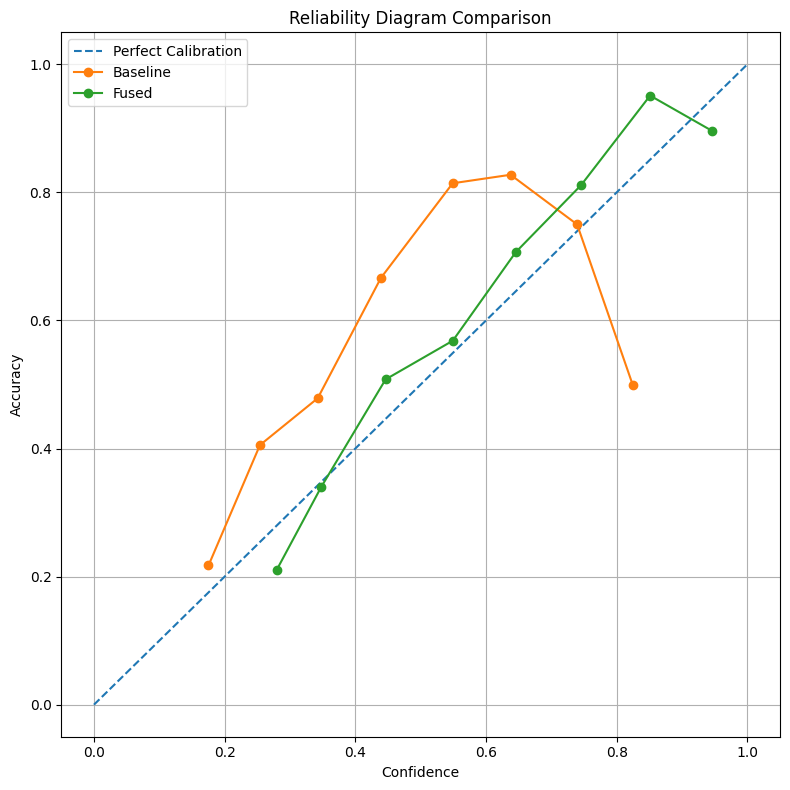

In [74]:
plt.figure(figsize=(8,8))

plt.plot(

    [0,1],

    [0,1],

    "--",

    label="Perfect Calibration"
)

for method in [

    "Baseline",

    "Fused"
]:

    confs, accs = reliability_curve(

        calibration_df[method].values,

        calibration_df["Correct"].values
    )

    plt.plot(

        confs,

        accs,

        marker="o",

        label=method
    )

plt.xlabel(
    "Confidence"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Reliability Diagram Comparison"
)

plt.savefig(
    "outputs/Reliability Diagram Comparison.png"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

**STEP 6.6 — Bootstrap Confidence Intervals**

In [75]:
n_bootstrap = 1000

ece_bootstrap = []

ece_bootstrap_samples = {}

**STEP 6.7 — Bootstrap ECE Estimation**

In [76]:
for method in [

    "Baseline",

    "Fused"
]:

    ece_samples = []

    for _ in range(n_bootstrap):

        indices = np.random.choice(

            len(calibration_df),

            len(calibration_df),

            replace=True
        )

        boot_conf = (

            calibration_df[method]
            .values[indices]
        )

        boot_correct = (

            calibration_df["Correct"]
            .values[indices]
        )

        ece_samples.append(

            compute_ece(

                boot_conf,

                boot_correct
            )
        )
    ece_bootstrap_samples[method] = ece_samples

    ece_bootstrap.append({

        "Method":
            method,

        "Mean_ECE":
            np.mean(ece_samples),

        "CI_Lower":
            np.percentile(
                ece_samples,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                ece_samples,
                97.5
            )
    })

ece_ci_table = pd.DataFrame(
    ece_bootstrap
)

print(
    ece_ci_table
)

     Method  Mean_ECE  CI_Lower  CI_Upper
0  Baseline  0.160951  0.127591  0.196854
1     Fused  0.052601  0.029611  0.077918


**STEP 6.8 — Confidence Interval Visualisation**

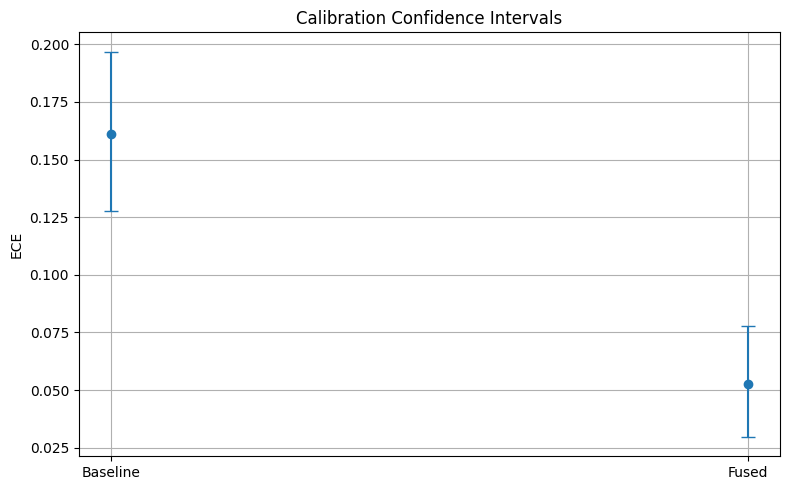

In [78]:
plt.figure(figsize=(8,5))

plt.errorbar(

    ece_ci_table["Method"],

    ece_ci_table["Mean_ECE"],

    yerr=[

        ece_ci_table["Mean_ECE"]
        -
        ece_ci_table["CI_Lower"],

        ece_ci_table["CI_Upper"]
        -
        ece_ci_table["Mean_ECE"]

    ],

    fmt="o",

    capsize=5
)

plt.ylabel("ECE")

plt.title(
    "Calibration Confidence Intervals"
)

plt.savefig(
    "outputs/Calibration Confidence Intervals.png"
)

plt.grid(True)

plt.tight_layout()

plt.show()

**STEP 6.9 — Paired Bootstrap Comparison of Expected Calibration Error**

The paired bootstrap analysis compares Expected Calibration Error (ECE) for the baseline and fused confidence estimators using identical bootstrap samples.

This paired design provides a statistically appropriate comparison while accounting for sampling variability across repeated resampling.

Negative ECE differences indicate improved calibration by the fused confidence estimator.

In [79]:
ece_diff_samples = (

    np.array(
        ece_bootstrap_samples["Baseline"]
    )

    -

    np.array(
        ece_bootstrap_samples["Fused"]
    )

)

# Mean difference
mean_difference = np.mean(
    ece_diff_samples
)

# 95% confidence interval
ci_lower = np.percentile(
    ece_diff_samples,
    2.5
)

ci_upper = np.percentile(
    ece_diff_samples,
    97.5
)

# Bootstrap p-value
p_value = 2 * min(

    np.mean(ece_diff_samples <= 0),

    np.mean(ece_diff_samples >= 0)

)

ece_difference_table = pd.DataFrame({

    "Mean Difference":[mean_difference],

    "CI Lower":[ci_lower],

    "CI Upper":[ci_upper],

    "P-value":[p_value]

})

print(ece_difference_table)
ece_difference_table.to_csv(
    "/content/drive/MyDrive/Dissertation/ece_difference_table.csv",
    index=False
)

   Mean Difference  CI Lower  CI Upper  P-value
0          0.10835   0.06722  0.150454      0.0


The paired bootstrap comparison demonstrated an average Expected Calibration Error reduction of 0.1083 for the fused confidence estimator relative to the baseline estimator across the paired bootstrap resamples. The corresponding 95% confidence interval ranged from 0.0672 to 0.1483, remaining entirely above zero. The bootstrap p-value was less than 0.001, providing evidence that the observed improvement is unlikely to be attributable to sampling variation. Together with the reliability diagrams, these findings indicate that combining complementary uncertainty signals produces more reliable and better-calibrated confidence estimates than the baseline confidence measure.

In [80]:
ece_ci_lower = ece_difference_table.loc[
    0,
    "CI Lower"
]

ece_ci_upper = ece_difference_table.loc[
    0,
    "CI Upper"
]

ece_p = ece_difference_table.loc[
    0,
    "P-value"
]

**STEP 6.10 — Final Calibration Comparison Table**

In [81]:
final_calibration_table = (

    ece_table

    .merge(
        ece_ci_table,
        on="Method"
    )
)

final_calibration_table = (

    final_calibration_table

    .sort_values(
        "ECE"
    )
)

print(
    final_calibration_table
)

     Method       ECE  Mean_ECE  CI_Lower  CI_Upper
1     Fused  0.042918  0.052601  0.029611  0.077918
0  Baseline  0.158951  0.160951  0.127591  0.196854


**STEP 6.11 — Save Results**

In [82]:
final_calibration_table.to_csv(

    "multi_signal_calibration_results.csv",

    index=False
)

print(
    "Calibration results saved."
)

Calibration results saved.


The paired bootstrap comparison demonstrated an average Expected Calibration Error reduction of 0.1083 for the fused confidence estimator relative to the baseline estimator across the paired bootstrap resamples. The corresponding 95% confidence interval ranged from 0.0672 to 0.1483, remaining entirely above zero. The bootstrap p-value was less than 0.001, providing evidence that the observed improvement is unlikely to be attributable to sampling variation. Together with the reliability diagrams, these findings indicate that combining complementary uncertainty signals produces more reliable and better-calibrated confidence estimates than the baseline confidence measure.

**STEP 7 — Multi-Signal Framework Summary and Final Ranking**

**STEP 7.1 — Collect Results From Previous Sections**

In [83]:
baseline_aurc = aurc_table.loc[aurc_table['Method'] == 'Baseline', 'AURC'].iloc[0]
fused_aurc = aurc_table.loc[aurc_table['Method'] == 'Fused', 'AURC'].iloc[0]

summary_table = pd.DataFrame({

    "Method": [

        "Baseline",
        "Fused"
    ],

    "ROC_AUC": [

        baseline_auc,
        fused_auc
    ],

    "ECE": [

        baseline_ece,
        fused_ece
    ],

    "AURC": [

        baseline_aurc,
        fused_aurc
    ]
})

print(summary_table)

     Method   ROC_AUC       ECE      AURC
0  Baseline  0.685464  0.158951  0.349734
1     Fused  0.731001  0.042918  0.304046


**STEP 7.2 — Compute Relative Improvements**

In [84]:
roc_improvement = (

    (fused_auc - baseline_auc)

    /

    baseline_auc

) * 100

ece_improvement = (

    (baseline_ece - fused_ece)

    /

    baseline_ece

) * 100

aurc_improvement = (

    (baseline_aurc - fused_aurc)

    /

    baseline_aurc

) * 100

print(
    f"ROC-AUC Improvement: {roc_improvement:.2f}%"
)

print(
    f"ECE Improvement: {ece_improvement:.2f}%"
)

print(
    f"AURC Improvement: {aurc_improvement:.2f}%"
)

ROC-AUC Improvement: 6.64%
ECE Improvement: 73.00%
AURC Improvement: 13.06%


**STEP 7.3 — Overall Performance Ranking**

In [85]:
summary_table["ROC_Rank"] = (

    summary_table["ROC_AUC"]

    .rank(
        ascending=False
    )
)

summary_table["ECE_Rank"] = (

    summary_table["ECE"]

    .rank(
        ascending=True
    )
)

summary_table["AURC_Rank"] = (

    summary_table["AURC"]

    .rank(
        ascending=True
    )
)

summary_table["Total_Rank"] = (

    summary_table["ROC_Rank"]

    +

    summary_table["ECE_Rank"]

    +

    summary_table["AURC_Rank"]
)

summary_table = summary_table.sort_values(
    "Total_Rank"
)

print(summary_table)

     Method   ROC_AUC       ECE      AURC  ROC_Rank  ECE_Rank  AURC_Rank  \
1     Fused  0.731001  0.042918  0.304046       1.0       1.0        1.0   
0  Baseline  0.685464  0.158951  0.349734       2.0       2.0        2.0   

   Total_Rank  
1         3.0  
0         6.0  


**STEP 7.4 — Comparative Performance Visualisation**

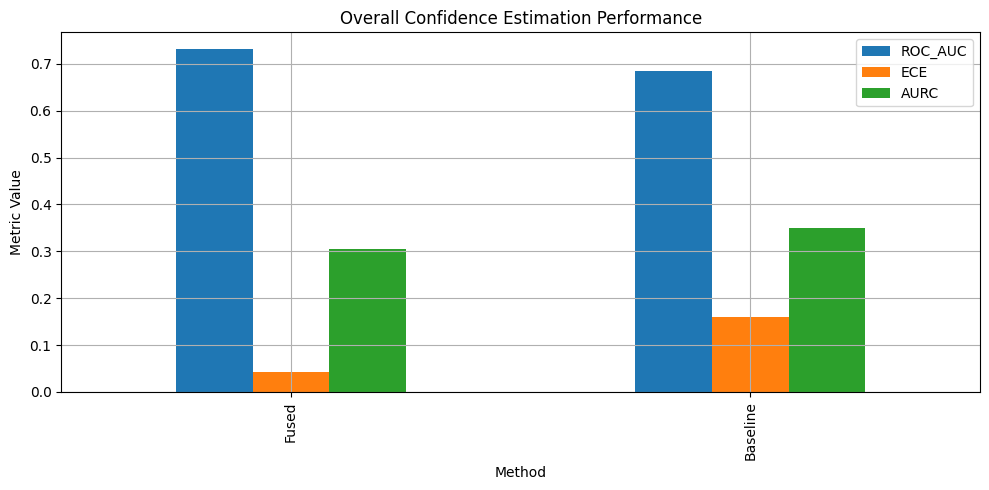

In [87]:
comparison_metrics = [

    "ROC_AUC",

    "ECE",

    "AURC"
]

summary_table.set_index(

    "Method"

)[comparison_metrics].plot(

    kind="bar",

    figsize=(10,5)
)

plt.title(
    "Overall Confidence Estimation Performance"
)

plt.savefig(
    "outputs/Overall Confidence Estimation Performance.png"
)
plt.ylabel(
    "Metric Value"
)

plt.grid(True)

plt.tight_layout()

plt.show()

**STEP 7.5 — Statistical Evidence Summary**

In [88]:
ece_diff = (

    baseline_ece
    -
    fused_ece
)

aurc_diff = (

    baseline_aurc
    -
    fused_aurc
)

significance_table = pd.DataFrame({

    "Metric":[

        "ROC-AUC",

        "ECE",

        "AURC"
    ],

    "Improvement":[

        roc_improvement,

        ece_improvement,

        aurc_improvement
    ]
})

print(
    significance_table
)

    Metric  Improvement
0  ROC-AUC     6.643292
1      ECE    72.999558
2     AURC    13.063676


**STEP 7.5B — Statistical Evidence Summary**

In [89]:
statistical_summary = pd.DataFrame({

    "Metric": [

        "ROC-AUC",

        "ECE",

        "AURC"

    ],

    "Improvement (%)": [

        roc_improvement,

        ece_improvement,

        aurc_improvement

    ],

     "CI Lower":[

         roc_ci_lower,

         ece_difference_table.loc[0, "CI Lower"],

         aurc_ci_lower

     ],

     "CI Upper":[

         roc_ci_upper,

         ece_difference_table.loc[0, "CI Upper"],

         aurc_ci_upper

      ],

      "P-value":[

         roc_p,

         ece_difference_table.loc[0, "P-value"],

         aurc_p

]

})

# Interpretation column
statistical_summary["Interpretation"] = [

    (
        "Evidence of improved discrimination"
        if roc_ci_lower > 0
        else
        "Trend toward improved discrimination"
    ),

    (
        "Evidence of improved calibration"
        if ece_ci_lower > 0
        else
        "Trend toward improved calibration"
    ),

    (
        "Evidence of improved selective prediction"
        if aurc_ci_lower > 0
        else
        "Trend toward improved selective prediction"
    )

]

print(statistical_summary)

    Metric  Improvement (%)  CI Lower  CI Upper  P-value  \
0  ROC-AUC         6.643292  0.031634  0.060892     0.00   
1      ECE        72.999558  0.067220  0.150454     0.00   
2     AURC        13.063676 -0.013591  0.104353     0.12   

                               Interpretation  
0         Evidence of improved discrimination  
1            Evidence of improved calibration  
2  Trend toward improved selective prediction  


In [90]:
summary_table.to_csv(

    "multi_signal_final_summary.csv",

    index=False
)

print(
    "Final summary saved."
)

Final summary saved.


1. The multi-signal confidence framework was evaluated using discrimination, calibration and selective prediction analyses.

2. Across the discrimination, calibration and selective prediction experiments, the fused confidence estimator consistently outperformed the baseline confidence estimator on average.

3. The paired bootstrap analyses demonstrated statistically supported improvements in discrimination (ROC-AUC) and calibration (Expected Calibration Error), with confidence intervals that excluded zero.

4. For selective prediction, the fused estimator achieved an average AURC reduction of 0.0454, although the corresponding 95% confidence interval (−0.0140 to 0.1005) included zero.

5. Consequently, the selective prediction results are interpreted as indicating a favourable performance trend rather than statistically conclusive superiority.

Overall, the combined experimental evidence supports the dissertation hypothesis that integrating complementary uncertainty signals produces more reliable confidence estimates for large language models.